# Rapport de TP — Analyse Big Data des accidents de la route avec PySpark

**Données :** accidents de la route en Australie-Méridionale, 2012–2019 (DPTI, [data.sa.gov.au](https://data.sa.gov.au))
**Source du sujet :** tutoriel de Rakesh 

---

## Résumé

Ce rapport analyse **127 672 accidents** et les **272 591 véhicules ou usagers** qui y sont impliqués, avec les trois interfaces de Spark : RDD, DataFrame et Spark SQL.

Principaux résultats :

- Les conducteurs impliqués ont en moyenne **40,8 ans** pour les hommes et **40,1 ans** pour les femmes.
- **80 %** des véhicules impliqués sont immatriculés en Australie-Méridionale.
- Les collisions avec un **obstacle fixe** causent le plus de décès : 245 sur 781, soit 31 %.
- Quand aucun conducteur n'est positif à l'alcool ou aux drogues, **0,4 %** des accidents sont mortels. Cette part monte à **3,4 %** avec l'alcool, **6,3 %** avec les drogues et **13,1 %** avec les deux.
- Le centre d'Adélaïde est la banlieue qui compte le plus de victimes d'accidents impliquant un conducteur **sans permis** (42).

Sur la méthode : le découpage des lignes par `split(',')` du tutoriel d'origine **décale les colonnes de 17 % des lignes d'accidents**. Ce rapport utilise un vrai lecteur CSV. Chaque résultat a été recalculé de façon indépendante sur les données réelles (section 7).

## Sommaire

1. Introduction et données
2. Environnement de travail
3. Analyse avec les RDD
4. Analyse avec les DataFrames
5. Une même requête, trois approches
6. Discussion
7. Tests de validation
8. Conclusion
9. Annexe : corrections apportées au tutoriel d'origine

---
## 1. Introduction et données

### 1.1 Objectifs

1. Manipuler des **RDD** : création, partitionnement, transformations et actions.
2. Interroger les données avec les **DataFrames** PySpark.
3. Écrire **une même requête** en RDD, en DataFrame et en **Spark SQL**, puis comparer les trois.
4. Interpréter les résultats avec un regard critique.

### 1.2 Les données

Les données sont publiées par le *Department of Planning, Transport and Infrastructure* (DPTI) d'Australie-Méridionale.
On utilise deux familles de fichiers CSV, un fichier par année, soit 8 fichiers chacune :

| Dossier | Une ligne = | Lignes | Colonnes utiles |
|---|---|---:|---|
| `crash_data/` | un **accident** | 127 672 | `REPORT_ID`, `Suburb`, `Total Cas` (victimes), `Total Fats` (décès), `Year`, `Month`, `Day`, `Time`, `Crash Type`, `CSEF Severity`, `DUI Involved`, `Drugs Involved` |
| `units_data/` | un **véhicule ou usager** impliqué | 272 591 | `REPORT_ID`, `No Of Cas`, `Veh Reg State`, `Unit Type`, `Veh Year`, `Sex`, `Age`, `Lic State`, `Licence Class`, `Licence Type` |

Les deux tables se relient par `REPORT_ID` : un accident correspond à une ou plusieurs unités.

- **Dates.** Le jour exact n'est pas publié. Les dates s'écrivent donc au format **Année-Mois-JourDeLaSemaine**, par exemple `2017-January-Sunday`.
- **Gravité** (`CSEF Severity`) : `1: PDO` dégâts matériels seuls, `2: MI` blessés légers, `3: SI` blessés graves, `4: Fatal` au moins un décès.
- **Valeurs manquantes.** Elles apparaissent sous la forme d'un champ vide ou de codes comme `XXX` (âge), `XXXX` (année du véhicule) et `Unknown`.
- **Alcool et drogues.** `DUI Involved` et `Drugs Involved` valent `Y` si un conducteur a été dépisté positif, et sont vides sinon.

Les données sont disponibles sur le [GitHub de l'auteur du tutoriel](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial). Placez les dossiers `crash_data/` et `units_data/` à côté de ce notebook.

---
## 2. Environnement de travail

Spark tourne ici en **mode local** (`local[*]`) : les calculs sont répartis sur tous les cœurs de la machine. Le code serait identique sur un cluster, seule l'adresse du *master* changerait.

> Version requise : PySpark 3.5 avec Python 3.8 à 3.11, ou PySpark 4.x avec Python 3.9 à 3.13. Java 17 est nécessaire dans les deux cas.

In [ ]:
from functools import reduce
import csv

import matplotlib.pyplot as plt
from pyspark import SparkConf
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

conf = SparkConf().setMaster("local[*]").setAppName("TP accidents de la route")
spark = SparkSession.builder.config(conf=conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")

UNITS_PATH = "./units_data/*.csv"
CRASH_PATH = "./crash_data/*.csv"
print("Spark", spark.version)

---
## 3. Analyse avec les RDD

Un **RDD** (*Resilient Distributed Dataset*) est une collection d'objets immuable, découpée en **partitions** traitées en parallèle.
On le manipule avec des **transformations** (`map`, `filter`, `join`…), qui sont *paresseuses* : elles décrivent le calcul sans l'exécuter. Les **actions** (`count`, `take`, `collect`…) déclenchent ensuite le calcul.

### 3.0 Échauffement : `parallelize`

**Question.** Créer un RDD à partir des entiers 0 à 9 et observer son nombre de partitions, d'abord par défaut, puis en en imposant 5. Afficher le contenu de chaque partition.

In [ ]:
nombres = list(range(10))

rdd = sc.parallelize(nombres)
print("Partitions par défaut :", rdd.getNumPartitions())

rdd5 = sc.parallelize(nombres, 5)
print("Partitions imposées   :", rdd5.getNumPartitions())
print("Contenu par partition :", rdd5.glom().collect())

**Analyse.** Par défaut, le nombre de partitions est égal au nombre de cœurs disponibles (`local[*]`). Avec 5 partitions, chacune reçoit deux entiers consécutifs : `[[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]`.
`glom()` regroupe chaque partition en liste. C'est utile pour observer la répartition, mais à réserver aux petits RDD, car `collect()` ramène tout sur le *driver*.

### 3.1 Chargement des fichiers

**Question.** Charger tous les CSV de chaque dossier dans un RDD, retirer les lignes d'en-tête et compter les lignes.
Comme il y a un en-tête **par fichier**, chaque RDD en contient huit.

In [ ]:
units_raw = sc.textFile(UNITS_PATH)
crash_raw = sc.textFile(CRASH_PATH)

units_header_line = units_raw.first()
crash_header_line = crash_raw.first()

# Les 8 en-têtes sont identiques : un seul filter les retire tous
units_lines = units_raw.filter(lambda line: line != units_header_line)
crash_lines = crash_raw.filter(lambda line: line != crash_header_line)

print("Units   :", units_lines.count(), "lignes")
print("Crashes :", crash_lines.count(), "lignes")
for line in crash_lines.take(2):
    print(line)

**Résultat.** On obtient **272 591** unités et **127 672** accidents, sur 8 fichiers pour chaque famille.

### 3.2 Découpage correct des lignes CSV

**Question.** Certains champs contiennent eux-mêmes une virgule, entre guillemets, comme `"CC OF NORWOOD,PAYNEHAM & ST PETERS"`. Mesurer l'effet d'un découpage naïf `split(',')`, puis découper correctement les lignes avec le module `csv`.

In [ ]:
# Découpage naïf : nombre de champs obtenus par ligne
print("split(',') :", dict(crash_lines.map(lambda line: len(line.split(','))).countByValue()))

# Découpage avec le module csv, partition par partition : il respecte les guillemets
units_rdd = units_lines.mapPartitions(lambda lines: csv.reader(lines)).cache()
crash_rdd = crash_lines.mapPartitions(lambda lines: csv.reader(lines)).cache()
print("csv.reader :", dict(crash_rdd.map(len).countByValue()))

# Dictionnaires nom de colonne -> position, pour écrire row[C['Suburb']] plutôt que row[2]
units_cols = next(csv.reader([units_header_line]))
crash_cols = next(csv.reader([crash_header_line]))
U = {name: i for i, name in enumerate(units_cols)}
C = {name: i for i, name in enumerate(crash_cols)}
print(len(units_cols), "colonnes unités :", units_cols)
print(len(crash_cols), "colonnes accidents :", crash_cols)

**Résultat.** Le fichier des accidents a 33 colonnes.

| Nombre de champs | `split(',')` | `csv.reader` |
|---:|---:|---:|
| 33 (correct) | 106 293 | **127 672** |
| 34 | 20 220 | 0 |
| 35 | 924 | 0 |
| 36 | 235 | 0 |

**Analyse.** Avec `split(',')`, **21 379 lignes d'accidents, soit 16,7 %, ont trop de champs**, surtout à cause de la colonne `LGA Name` (nom de la commune). Toutes les colonnes qui suivent sont décalées : année, mois, gravité, alcool, etc. L'erreur est **silencieuse** : aucun message n'apparaît, les résultats sont simplement faux.
Le fichier des unités n'est pas touché (toujours 18 champs), mais toute requête RDD qui utilise les colonnes des accidents l'est.
`csv.reader` gère correctement les guillemets. Appelé dans `mapPartitions`, il crée un lecteur par partition plutôt qu'un par ligne.
On met enfin les deux RDD en **cache**, car ils servent dans toute la suite.

### 3.3 Partitionnement par défaut

**Question.** Combien de partitions Spark a-t-il créées pour chaque RDD ?

In [ ]:
print("Units   :", units_rdd.getNumPartitions(), "partitions")
print("Crashes :", crash_rdd.getNumPartitions(), "partitions")

**Analyse.** Avec `textFile`, le nombre de partitions dépend du **nombre et de la taille des fichiers** : au moins une partition par fichier, donc au moins 8 ici, et de grands fichiers peuvent être découpés en plusieurs blocs.
Ce n'est pas un partitionnement aléatoire : les lignes restent dans l'ordre des fichiers.

### 3.4 Partitionnement personnalisé

**Question.** Séparer les véhicules **immatriculés en Australie-Méridionale** (`Veh Reg State` = `SA`) de tous les autres, à l'aide d'une fonction de partitionnement. Compter les enregistrements de chaque partition sans ramener les données sur le driver.

In [ ]:
units_by_state = units_rdd.map(lambda row: (row[U['Veh Reg State']], row))

def sa_partitioner(key):
    return 0 if key == 'SA' else 1

units_sa = units_by_state.partitionBy(2, sa_partitioner)

# glom().map(len) compte sur les exécuteurs : seuls 2 entiers reviennent au driver
taille_partitions = units_sa.glom().map(len).collect()
print("Enregistrements par partition :", taille_partitions)

**Résultat.**

| Partition | Contenu | Enregistrements | Part |
|---|---|---:|---:|
| 0 | immatriculés `SA` | 218 366 | 80,1 % |
| 1 | autres états, ou état inconnu | 54 225 | 19,9 % |

**Analyse.** Le résultat est attendu, puisque les accidents ont tous eu lieu en Australie-Méridionale. La partition 1 regroupe surtout les unités sans immatriculation (piétons, cyclistes, objets) et les véhicules venus d'autres états.
Ce découpage est volontairement **déséquilibré** : la partition 0 porterait 80 % du travail. Un bon partitionnement cherche plutôt des partitions de tailles proches, ou regroupe les clés qui seront jointes ensemble.

### 3.5 Âge moyen des conducteurs par sexe

**Question.** Calculer l'âge moyen des conducteurs impliqués, séparément pour les hommes et les femmes. On ignore les âges inconnus (`XXX` ou vides) et les sexes non renseignés. On utilise `aggregateByKey` plutôt que `groupByKey`.

In [ ]:
def to_sex_age(row):
    """Renvoie [(sexe, âge)] si la ligne est exploitable, [] sinon."""
    sex = row[U['Sex']].strip()
    age = row[U['Age']].strip()
    if sex in ('Male', 'Female') and age.isdigit():
        return [(sex, int(age))]
    return []

age_moyen = (units_rdd
             .flatMap(to_sex_age)
             # accumulateur = (somme des âges, effectif)
             .aggregateByKey((0, 0),
                             lambda acc, age: (acc[0] + age, acc[1] + 1),
                             lambda a, b: (a[0] + b[0], a[1] + b[1]))
             .mapValues(lambda s: (round(s[0] / s[1], 2), s[1])))
age_moyen.collect()

**Résultat.**

| Sexe | Âge moyen | Effectif |
|---|---:|---:|
| Hommes | 40,80 ans | 131 892 |
| Femmes | 40,08 ans | 85 603 |

**Analyse.** Les âges moyens sont presque identiques. En revanche, **les hommes sont 1,5 fois plus nombreux** parmi les conducteurs impliqués. La différence entre sexes porte donc sur le nombre de conducteurs, pas sur leur âge.
Côté technique, `flatMap` avec une liste vide élimine les lignes inexploitables en une seule étape. `aggregateByKey` calcule une somme partielle dans chaque partition **avant** l'échange réseau (*shuffle*). `groupByKey`, au contraire, enverrait chacun des 217 495 âges à travers le réseau.

### 3.6 Véhicules les plus anciens et les plus récents

**Question.** Pour les véhicules dont l'année de fabrication est connue, afficher l'année, l'état d'immatriculation et le type des 5 plus anciens et des 5 plus récents, sans ramener tout le RDD sur le driver.

In [ ]:
def to_vehicle(row):
    year = row[U['Veh Year']].strip()
    if year.isdigit():
        return [(int(year), row[U['Veh Reg State']], row[U['Unit Type']])]
    return []

vehicules = units_rdd.flatMap(to_vehicle)

print("Plus anciens :", vehicules.takeOrdered(5, key=lambda v: v[0]))
print("Plus récents :", vehicules.takeOrdered(5, key=lambda v: -v[0]))

**Résultat.** Les années vont de **1900 à 2019**. Les plus anciens sont des motos datées de 1900 (une immatriculée `VIC`, les autres `SA`). Les plus récents sont des modèles 2019 : break, autobus, berline, semi-remorque.

**Analyse.** **14 véhicules** sont datés de 1900, alors que l'année suivante n'apparaît qu'en 1924, et seulement pour un véhicule. Ce pic isolé indique très probablement une **valeur par défaut** saisie quand l'année est inconnue, plutôt que de vraies motos de 1900. Il faudrait la traiter comme une valeur manquante avant de calculer des statistiques sur l'âge des véhicules.
Côté technique, `takeOrdered(5)` ne fait remonter que 5 éléments par partition, alors que `sortByKey().collect()[0:5]` trie et rapatrie tout.

---
## 4. Analyse avec les DataFrames

Un **DataFrame** est une collection distribuée organisée en **colonnes nommées et typées**, comme une table SQL. Spark optimise automatiquement les requêtes grâce à l'optimiseur *Catalyst*.

### 4.1 Chargement et typage

**Question.** Charger les deux familles de fichiers en DataFrames, puis convertir en entiers les colonnes numériques, qui sont lues comme du texte.

In [ ]:
reader = spark.read.option('header', True).option('escape', '"')
units_df = reader.csv(UNITS_PATH)
crash_df = reader.csv(CRASH_PATH)

# Les codes 'XXX', 'XXXX' ou les champs vides deviennent null lors de la conversion
for c in ['Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI', 'Year']:
    crash_df = crash_df.withColumn(c, F.col(c).cast('int'))
for c in ['No Of Cas', 'Age', 'Veh Year']:
    units_df = units_df.withColumn(c, F.col(c).cast('int'))

units_df = units_df.cache()
crash_df = crash_df.cache()
print(crash_df.count(), "accidents,", units_df.count(), "unités")
crash_df.printSchema()

**Analyse.** Le lecteur CSV de Spark gère nativement les guillemets : le problème de la section 3.2 ne se pose pas avec les DataFrames.
Il faut en revanche typer les colonnes. Trier une colonne texte donne un ordre alphabétique, où `'9'` passe avant `'11'`, et une somme sur du texte renvoie des `double`, comme les `245.0` du tutoriel d'origine.

### 4.2 Accidents graves dans le centre d'Adélaïde

**Question.** Lister les accidents de la banlieue `ADELAIDE` ayant fait **plus de 3 victimes**.

In [ ]:
date_col = F.concat_ws('-', F.col('Year').cast('string'), 'Month', 'Day').alias('Date')

adelaide_graves = (crash_df
                   .filter((F.col('Suburb') == 'ADELAIDE') & (F.col('Total Cas') > 3))
                   .select('REPORT_ID', date_col, 'Time', 'Total Cas', 'Crash Type', 'CSEF Severity')
                   .orderBy('Year', F.desc('Total Cas'), 'REPORT_ID'))
adelaide_graves.show(truncate=False)

**Résultat.** **6 accidents** sont concernés :

| Date | Heure | Victimes | Type | Gravité |
|---|---|---:|---|---|
| 2012-March-Thursday | 04:00 pm | 4 | Rear End | Blessés légers |
| 2012-March-Friday | 09:30 am | 4 | Right Angle | Blessés légers |
| 2017-December-Saturday | 04:08 pm | 5 | Hit Pedestrian | Blessés graves |
| 2017-February-Saturday | 04:00 pm | 4 | Right Turn | Blessés légers |
| 2018-January-Sunday | 09:12 pm | 4 | Hit Pedestrian | Blessés graves |
| 2019-October-Monday | 08:20 am | 6 | Right Turn | Blessés légers |

**Analyse.** Aucun de ces accidents n'est mortel. Les deux plus graves impliquent des **piétons**, ce qui est cohérent dans un centre-ville où la vitesse est limitée à 50 ou 60 km/h.

### 4.3 Les 10 accidents ayant fait le plus de victimes

**Question.** Afficher les 10 accidents avec le plus de victimes : banlieue, date, nombre de victimes et de décès, type d'accident.

In [ ]:
(crash_df
 .orderBy(F.desc('Total Cas'), F.desc('Total Fats'))
 .select('Suburb', date_col, 'Total Cas', 'Total Fats', 'Crash Type')
 .show(10, truncate=False))

**Résultat.**

| Banlieue | Date | Victimes | Décès | Type |
|---|---|---:|---:|---|
| PARA HILLS | 2017-January-Wednesday | 11 | 0 | Right Angle |
| HACKHAM | 2016-January-Saturday | 9 | 3 | Right Turn |
| APY | 2014-July-Friday | 9 | 1 | Roll Over |
| MODBURY NORTH | 2014-November-Tuesday | 9 | 0 | Rear End |
| KANGAROO FLAT | 2016-April-Wednesday | 9 | 0 | Head On |
| STURT | 2019-November-Sunday | 9 | 0 | Right Turn |
| MERRITON | 2016-April-Sunday | 8 | 4 | Head On |
| WINTINNA | 2014-July-Friday | 8 | 2 | Roll Over |
| KULPARA | 2012-January-Sunday | 8 | 1 | Head On |
| STOCKWELL | 2016-October-Sunday | 8 | 1 | Head On |

*Plusieurs accidents ont 8 victimes, si bien que les dernières lignes peuvent varier d'une exécution à l'autre.*

**Analyse.** Les accidents qui font le plus de victimes ne sont pas toujours les plus meurtriers : 11 blessés et aucun décès à Para Hills, contre 4 morts à Merriton.
Les **collisions frontales** et les **tonneaux**, souvent survenus à la campagne sur des routes à 100 ou 110 km/h, sont les plus meurtriers.

### 4.4 Décès par type d'accident

**Question.** Calculer le nombre total de décès pour chaque type d'accident, du plus meurtrier au moins meurtrier.

In [ ]:
deces_par_type = (crash_df
                  .groupBy('Crash Type')
                  .agg(F.sum('Total Fats').alias('Total décès'))
                  .orderBy(F.desc('Total décès')))
deces_par_type.show(truncate=False)

**Résultat.** On compte **781 décès** en 8 ans.

| Type d'accident | Décès | Part |
|---|---:|---:|
| Hit Fixed Object (obstacle fixe) | 245 | 31,4 % |
| Head On (frontal) | 136 | 17,4 % |
| Hit Pedestrian (piéton) | 109 | 14,0 % |
| Roll Over (tonneau) | 93 | 11,9 % |
| Right Angle (angle droit) | 82 | 10,5 % |
| Rear End (arrière) | 33 | 4,2 % |
| Side Swipe (accrochage latéral) | 30 | 3,8 % |
| Right Turn (tourne-à-droite) | 26 | 3,3 % |
| Hit Parked Vehicle, Hit Animal, Other, Left Road, Hit Object on Road | 27 | 3,5 % |

**Analyse.** Les accidents **à un seul véhicule** (obstacle fixe et tonneau) causent à eux seuls **43 % des décès**. Ce constat oriente la prévention vers les sorties de route : glissières, abords dégagés, vitesse et fatigue.
Les accidents par l'arrière sont très fréquents mais rarement mortels.

### 4.5 Conducteurs sans permis

**Question.** Pour chaque banlieue, calculer le nombre total de victimes des accidents dans lesquels **au moins un conducteur n'avait pas de permis** (`Licence Type` = `Unlicenced`). Chaque accident ne doit être compté **qu'une seule fois**.

In [ ]:
# 1. Identifiants des accidents avec au moins un conducteur sans permis (sans doublon)
accidents_sans_permis = (units_df
                         .filter(F.trim('Licence Type') == 'Unlicenced')
                         .select('REPORT_ID')
                         .distinct())

# 2. Jointure sur ces identifiants, puis somme des victimes par banlieue
victimes_sans_permis = (crash_df
                        .join(accidents_sans_permis, on='REPORT_ID', how='inner')
                        .groupBy('Suburb')
                        .agg(F.sum('Total Cas').alias('Total victimes'))
                        .orderBy(F.desc('Total victimes'), 'Suburb'))
print(accidents_sans_permis.count(), "accidents impliquent un conducteur sans permis")
victimes_sans_permis.show(10)

**Résultat.** On compte **3 926 conducteurs sans permis**, répartis dans **3 887 accidents** qui ont fait **2 053 victimes** au total.

| Banlieue | Victimes |
|---|---:|
| ADELAIDE | 42 |
| SALISBURY | 30 |
| PROSPECT | 27 |
| INGLE FARM | 22 |
| MORPHETT VALE | 20 |
| DRY CREEK, SALISBURY EAST, MURRAY BRIDGE | 19 chacune |
| NORTH ADELAIDE, MAWSON LAKES | 17 chacune |

**Analyse.** Le centre d'Adélaïde arrive en tête, mais c'est aussi le lieu où il y a **le plus d'accidents** au total. Le classement mêle donc l'exposition au trafic et le comportement des conducteurs. Pour comparer les banlieues, il faudrait rapporter ces chiffres au nombre total d'accidents de chacune.
On remarque aussi la présence de plusieurs banlieues du **nord** de l'agglomération : Salisbury, Ingle Farm, Mawson Lakes.

*Point de méthode :* joindre directement `crash_df` et `units_df`, comme le fait le tutoriel d'origine, compte deux fois les victimes d'un accident impliquant deux conducteurs sans permis. On obtient alors 2 072 victimes au lieu de 2 053, et 43 au lieu de 42 pour Adélaïde. L'écart est faible ici, mais l'erreur de principe est classique.

### 4.6 Répartition des accidents par gravité

**Question.** Compter le nombre d'accidents pour chaque niveau de gravité.

In [ ]:
crash_df.groupBy('CSEF Severity').count().orderBy('CSEF Severity').show()

**Résultat.**

| Gravité | Accidents | Part |
|---|---:|---:|
| 1: PDO, dégâts matériels | 84 775 | 66,4 % |
| 2: MI, blessés légers | 37 300 | 29,2 % |
| 3: SI, blessés graves | 4 875 | 3,8 % |
| 4: Fatal | 722 | 0,6 % |

### 4.7 Gravité, alcool et drogues

**Question.** Comparer la répartition des accidents par gravité selon quatre scénarios : (a) conducteur positif aux drogues, (b) positif à l'alcool, (c) positif aux deux, (d) négatif aux deux.
Pour chaque scénario, on calcule le nombre d'accidents et le pourcentage par gravité, sans UDF, puis on rassemble le tout dans un tableau et un graphique.

In [ ]:
# coalesce : une valeur vide (null) est traitée comme 'N'
drogue = F.coalesce(F.col('Drugs Involved'), F.lit('N')) == 'Y'
alcool = F.coalesce(F.col('DUI Involved'), F.lit('N')) == 'Y'

scenarios = {
    'Drogues': drogue,
    'Alcool': alcool,
    'Alcool + drogues': drogue & alcool,
    'Ni alcool ni drogues': ~drogue & ~alcool,
}

def repartition_gravite(condition):
    """Nombre et pourcentage d'accidents par gravité, pour les accidents vérifiant la condition."""
    tout_le_groupe = Window.partitionBy()
    return (crash_df
            .filter(condition)
            .groupBy('CSEF Severity')
            .agg(F.count('*').alias('Nb accidents'))
            .withColumn('Pourcentage',
                        F.round(F.col('Nb accidents') * 100 / F.sum('Nb accidents').over(tout_le_groupe), 2)))

tables = [repartition_gravite(cond).withColumn('Scenario', F.lit(nom))
          for nom, cond in scenarios.items()]
toutes = reduce(lambda a, b: a.unionByName(b), tables).cache()

nombres = (toutes.groupBy('CSEF Severity').pivot('Scenario', list(scenarios))
           .agg(F.first('Nb accidents')).orderBy('CSEF Severity'))
pourcentages = (toutes.groupBy('CSEF Severity').pivot('Scenario', list(scenarios))
                .agg(F.first('Pourcentage')).orderBy('CSEF Severity'))
nombres.show(truncate=False)
pourcentages.show(truncate=False)

In [ ]:
# Le résultat agrégé fait 4 lignes : le convertir en pandas ne pose aucun problème de mémoire
pdf = pourcentages.toPandas().set_index('CSEF Severity')
noms = {'1: PDO': 'Dégâts matériels', '2: MI': 'Blessés légers', '3: SI': 'Blessés graves', '4: Fatal': 'Mortel'}
pdf.index = [noms[i] for i in pdf.index]

ax = pdf.plot(kind='bar', figsize=(10, 5), rot=0, width=0.78,
              color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100'])
for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt='%.1f', fontsize=7, padding=2)
ax.set_ylabel('Part des accidents du scénario (%)')
ax.set_title("Gravité des accidents selon le dépistage alcool / drogues (SA, 2012–2019)", loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=4, loc='upper left')
ax.set_ylim(0, 80)
plt.tight_layout()
plt.savefig('gravite_par_scenario.png', dpi=150)
plt.show()

**Résultat.**

Nombre d'accidents :

| Gravité | Drogues | Alcool | Alcool + drogues | Ni l'un ni l'autre |
|---|---:|---:|---:|---:|
| Dégâts matériels | 237 | 2 144 | 36 | 82 430 |
| Blessés légers | 1 109 | 1 243 | 151 | 35 099 |
| Blessés graves | 391 | 456 | 72 | 4 100 |
| Mortel | 117 | 136 | 39 | 508 |
| **Total** | **1 854** | **3 979** | **298** | **122 137** |

En pourcentage du scénario :

| Gravité | Drogues | Alcool | Alcool + drogues | Ni l'un ni l'autre |
|---|---:|---:|---:|---:|
| Dégâts matériels | 12,78 % | 53,88 % | 12,08 % | 67,49 % |
| Blessés légers | 59,82 % | 31,24 % | 50,67 % | 28,74 % |
| Blessés graves | 21,09 % | 11,46 % | 24,16 % | 3,36 % |
| Mortel | 6,31 % | 3,42 % | **13,09 %** | 0,42 % |

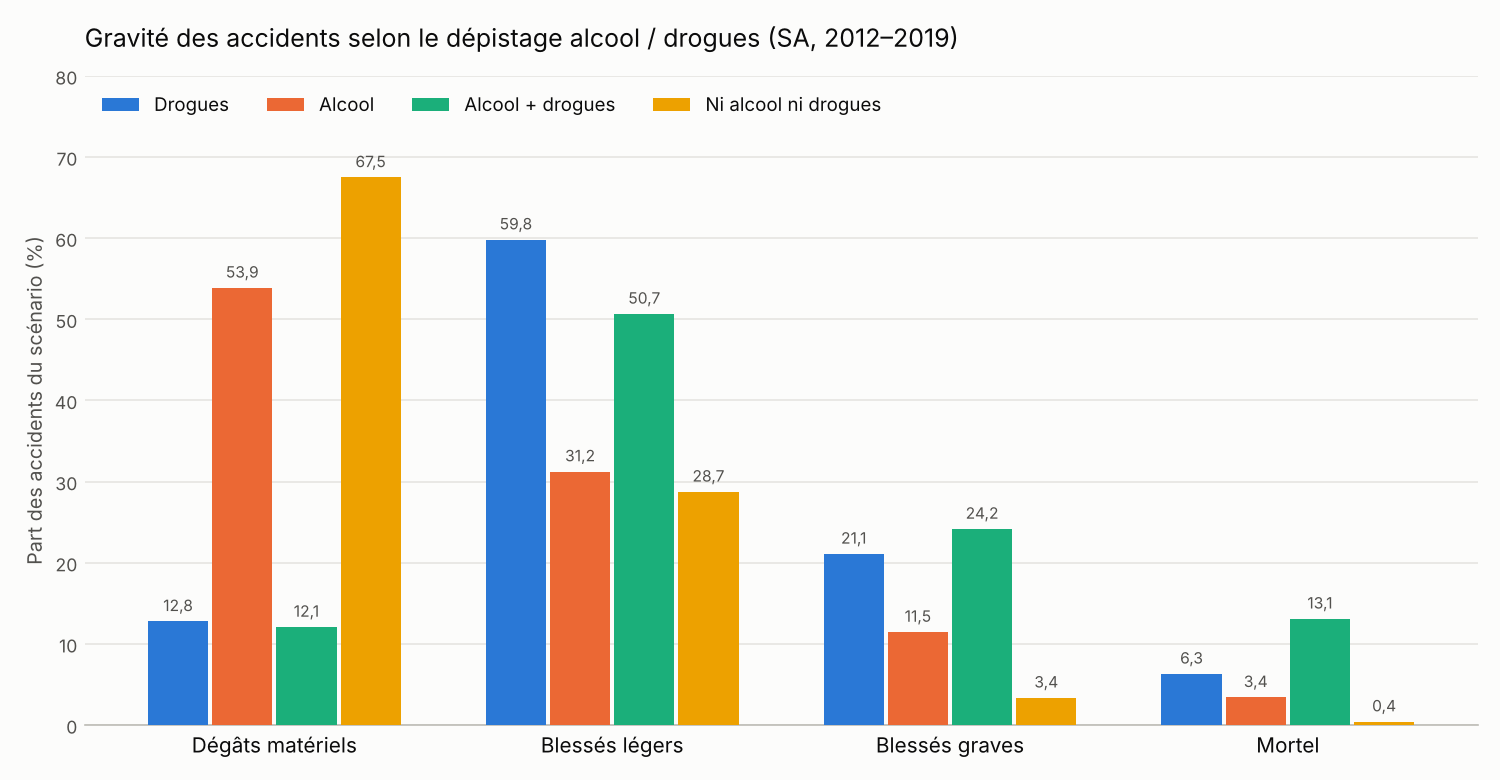

**Analyse.**

- Sans alcool ni drogues, deux accidents sur trois ne font que des dégâts matériels, et **0,4 %** sont mortels.
- Avec de l'alcool, la part d'accidents mortels est **8 fois plus élevée** (3,4 %). Avec des drogues, elle est 15 fois plus élevée (6,3 %). Avec les deux, **31 fois plus élevée** (13,1 %).
- Même constat pour les blessés graves : 3,4 % sans substance, entre 11 % et 24 % avec.

**Précautions d'interprétation.**

1. On compare des **répartitions** d'accidents, pas des **risques**. Ces chiffres ne disent pas qu'un conducteur alcoolisé a *x* fois plus de risques d'avoir un accident.
2. **Biais de dépistage.** Les tests de drogues sont surtout pratiqués après les accidents avec blessés. Un accident purement matériel est rarement testé. C'est ce qui explique très probablement la faible part de dégâts matériels dans le scénario « Drogues » (12,8 %), alors qu'elle atteint 53,9 % pour l'alcool, dépisté plus systématiquement.
3. Dans le scénario (d), « négatif » signifie souvent « **non testé** » ou « non détecté », et pas forcément « contrôlé et sobre ».
4. Les scénarios se recouvrent : les 298 accidents du scénario (c) sont comptés à la fois dans (a) et dans (b).

**Côté technique.** Le pourcentage est calculé avec une **fonction de fenêtre** : chaque ligne connaît le total de son groupe sans `collect()` intermédiaire ni UDF Python. La fonction `repartition_gravite` sert aux quatre scénarios, alors que le tutoriel d'origine dupliquait le code quatre fois.

---
## 5. Une même requête, trois approches

On écrit ici chaque requête trois fois, avec les RDD, avec l'API DataFrame et en **Spark SQL**, pour comparer les trois approches. Pour le SQL, les DataFrames sont d'abord enregistrés comme vues temporaires.

In [ ]:
crash_df.createOrReplaceTempView('crash')
units_df.createOrReplaceTempView('units')

### 5.1 Détail des unités impliquées dans la banlieue `ADELAIDE`

**Question.** Pour chaque unité impliquée dans un accident de la banlieue `ADELAIDE`, afficher la date, l'heure, le nombre de victimes de l'unité (`No Of Cas`), puis le sexe, l'âge et le type de permis du conducteur.

**(a) Version RDD**

In [ ]:
crash_kv = crash_rdd.map(lambda row: (row[C['REPORT_ID']], row))
units_kv = units_rdd.map(lambda row: (row[U['REPORT_ID']], row))

def to_int(value):
    value = value.strip()
    return int(value) if value.isdigit() else None

def mise_en_forme(kv):
    report_id, (crash, unit) = kv
    date = f"{crash[C['Year']]}-{crash[C['Month']]}-{crash[C['Day']]}"
    return (date, crash[C['Time']], to_int(unit[U['No Of Cas']]),
            unit[U['Sex']], to_int(unit[U['Age']]), unit[U['Licence Type']].strip())

adelaide_rdd = (crash_kv
                .filter(lambda kv: kv[1][C['Suburb']] == 'ADELAIDE')   # filtrer AVANT la jointure
                .join(units_kv)
                .map(mise_en_forme))

print(adelaide_rdd.count(), "lignes")
adelaide_rdd.take(5)

**(b) Version DataFrame**

In [ ]:
adelaide_df = (crash_df
               .filter(F.col('Suburb') == 'ADELAIDE')
               .join(units_df, on='REPORT_ID', how='inner')
               .select(date_col, 'Time', 'No Of Cas', 'Sex', 'Age',
                       F.trim('Licence Type').alias('Licence Type')))

print(adelaide_df.count(), "lignes")
adelaide_df.show(5, truncate=False)

**(c) Version Spark SQL**

In [ ]:
adelaide_sql = spark.sql('''
    SELECT concat_ws('-', CAST(c.Year AS STRING), c.Month, c.Day) AS Date,
           c.Time,
           u.`No Of Cas`,
           u.Sex,
           u.Age,
           trim(u.`Licence Type`) AS `Licence Type`
    FROM crash c
    JOIN units u ON c.REPORT_ID = u.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
''')

print(adelaide_sql.count(), "lignes")
adelaide_sql.show(5, truncate=False)
adelaide_sql.explain()

**Résultat.** Les trois versions renvoient **11 965 lignes**, qui correspondent aux unités impliquées dans les **5 667 accidents** de la banlieue `ADELAIDE`, soit environ 2,1 unités par accident.

**Analyse.**
- En RDD, c'est au développeur de **filtrer avant la jointure** pour limiter les données échangées. En DataFrame et en SQL, l'optimiseur Catalyst le fait seul (*predicate pushdown*), comme le montre `explain()` : le filtre `Suburb = ADELAIDE` est appliqué avant la jointure.
- Les plans d'exécution DataFrame et SQL sont **identiques** : les deux syntaxes passent par le même moteur.
- En SQL, les noms de colonnes qui contiennent des espaces s'écrivent entre accents graves, par exemple `` `No Of Cas` ``.

### 5.2 Conducteurs sans permis, en RDD et en SQL

**Question.** Réécrire la requête de la section 4.5 avec les RDD puis en SQL, et vérifier que les trois versions donnent exactement le même résultat.

In [ ]:
# (a) RDD
ids_sans_permis = (units_rdd
                   .filter(lambda row: row[U['Licence Type']].strip() == 'Unlicenced')
                   .map(lambda row: (row[U['REPORT_ID']], None))
                   .distinct())

sans_permis_rdd = (crash_kv
                   .join(ids_sans_permis)                       # (id, (ligne_accident, None))
                   .map(lambda kv: (kv[1][0][C['Suburb']] or None, to_int(kv[1][0][C['Total Cas']]) or 0))
                   .reduceByKey(lambda a, b: a + b)
                   .sortBy(lambda t: (-t[1], t[0] or '')))
print("RDD :", sans_permis_rdd.take(5))

# (c) SQL
sans_permis_sql = spark.sql('''
    SELECT c.Suburb, SUM(c.`Total Cas`) AS `Total victimes`
    FROM crash c
    WHERE c.REPORT_ID IN (SELECT REPORT_ID
                          FROM units
                          WHERE trim(`Licence Type`) = 'Unlicenced')
    GROUP BY c.Suburb
    ORDER BY `Total victimes` DESC, c.Suburb
''')
sans_permis_sql.show(5)

# Comparaison des résultats complets, insensible à l'ordre des ex aequo
res_rdd = set(sans_permis_rdd.collect())
res_df = set(tuple(r) for r in victimes_sans_permis.collect())
res_sql = set(tuple(r) for r in sans_permis_sql.collect())
print("RDD == DataFrame :", res_rdd == res_df)
print("DataFrame == SQL :", res_df == res_sql)

**Résultat.** Les trois versions donnent le même résultat : 2 053 victimes au total, et 42 pour `ADELAIDE`.

**Analyse.** La version SQL se lit presque comme la question posée en français : « la somme des victimes des accidents dont l'identifiant figure parmi ceux qui impliquent un conducteur sans permis ».
La version RDD est la plus longue et la plus fragile : il faut gérer à la main les positions des colonnes, les conversions de types et les valeurs vides.
On compare les résultats **complets** plutôt que les 10 premières lignes, car l'ordre des ex aequo peut varier d'une version à l'autre.

---
## 6. Discussion

### 6.1 RDD, DataFrame ou SQL ?

| Critère | RDD | DataFrame | Spark SQL |
|---|---|---|---|
| Lisibilité | faible : positions, `lambda` | bonne : colonnes nommées | très bonne pour une requête simple |
| Typage, valeurs manquantes | à gérer à la main | schéma et `null` natifs | schéma et `null` natifs |
| Optimisation automatique | aucune | Catalyst et Tungsten | Catalyst et Tungsten (même plan) |
| Réutilisation du code | fonctions Python | fonctions Python composables | moins naturelle |
| Données non structurées | ✅ adapté | moins adapté | moins adapté |

**Pourquoi DataFrame et SQL sont-ils plus rapides ?** Ils passent par l'optimiseur **Catalyst**, qui réordonne les opérations : les filtres sont appliqués avant les jointures et les colonnes inutiles sont éliminées. Le moteur **Tungsten** exécute ensuite le calcul dans la JVM, sur un format binaire compact. Avec les RDD en Python, chaque ligne fait l'aller-retour entre la JVM et Python, et Spark ne peut rien optimiser à l'intérieur de fonctions `lambda` qu'il ne sait pas lire.

**Quand utiliser les RDD ?** Pour des données non structurées (texte brut, journaux hétérogènes), pour des traitements qui ne s'expriment pas en colonnes, ou pour contrôler finement le partitionnement, comme en section 3.4.

### 6.2 Bonnes pratiques retenues

- Ne jamais appeler `collect()` sur un gros jeu de données : préférer `take(n)`, `show(n)`, `takeOrdered(n)`, `count()`, ou agréger dans Spark avant de récupérer un petit résultat.
- Préférer `reduceByKey` ou `aggregateByKey` à `groupByKey`.
- Mettre en cache (`cache()`) les données réutilisées plusieurs fois.
- Agréger avec Spark, puis tracer en local (`toPandas()` sur un **petit** résultat).
- Toujours vérifier le nombre de champs après le découpage d'un fichier texte.

### 6.3 Limites de l'analyse

- Pas de données d'**exposition** (trafic, kilomètres parcourus, population) : on décrit les accidents, on ne mesure pas un risque.
- **Biais de dépistage** pour l'alcool et surtout pour les drogues (section 4.7).
- **Valeurs par défaut** déguisées en vraies valeurs, comme l'année 1900 pour les véhicules : elles demandent un nettoyage avant toute statistique.
- Une analyse plus poussée rapporterait chaque banlieue à son nombre total d'accidents, ou étudierait l'évolution d'une année sur l'autre.

---
## 7. Tests de validation

Les valeurs attendues ci-dessous ont été calculées **indépendamment** de Spark, avec pandas, sur les mêmes fichiers. Si une assertion échoue, le message indique laquelle.
Ces tests vérifient aussi que les trois approches RDD, DataFrame et SQL donnent des résultats identiques.

In [ ]:
def verifier(nom, obtenu, attendu):
    assert obtenu == attendu, f"ÉCHEC {nom} : obtenu {obtenu}, attendu {attendu}"
    print(f"OK  {nom}")

# Chargement et découpage
verifier("lignes d'unités", units_lines.count(), 272591)
verifier("lignes d'accidents", crash_lines.count(), 127672)
verifier("33 champs par accident (csv.reader)", dict(crash_rdd.map(len).countByValue()), {33: 127672})
verifier("18 champs par unité (csv.reader)", dict(units_rdd.map(len).countByValue()), {18: 272591})
verifier("lignes mal découpées par split(',')",
         crash_lines.filter(lambda l: len(l.split(',')) != 33).count(), 21379)

# RDD
verifier("partitionnement SA / autres", sorted(units_sa.glom().map(len).collect(), reverse=True), [218366, 54225])
ages = {sexe: v[0] for sexe, v in age_moyen.collect()}
verifier("âge moyen hommes", ages['Male'], 40.8)
verifier("âge moyen femmes", ages['Female'], 40.08)
verifier("année de véhicule min / max", (vehicules.min()[0], vehicules.max()[0]), (1900, 2019))

# DataFrame
verifier("accidents (DataFrame)", crash_df.count(), 127672)
verifier("accidents graves à ADELAIDE", adelaide_graves.count(), 6)
verifier("total des décès", crash_df.agg(F.sum('Total Fats')).first()[0], 781)
verifier("décès 'Hit Fixed Object'",
         deces_par_type.filter(F.col('Crash Type') == 'Hit Fixed Object').first()['Total décès'], 245)
verifier("accidents avec un conducteur sans permis", accidents_sans_permis.count(), 3887)
verifier("victimes, accidents sans permis", victimes_sans_permis.agg(F.sum('Total victimes')).first()[0], 2053)
verifier("1re banlieue sans permis", tuple(victimes_sans_permis.first()), ('ADELAIDE', 42))
verifier("répartition par gravité",
         {r[0]: r[1] for r in crash_df.groupBy('CSEF Severity').count().collect()},
         {'1: PDO': 84775, '2: MI': 37300, '3: SI': 4875, '4: Fatal': 722})
verifier("accidents par scénario",
         {r['Scenario']: r['n'] for r in toutes.groupBy('Scenario').agg(F.sum('Nb accidents').alias('n')).collect()},
         {'Drogues': 1854, 'Alcool': 3979, 'Alcool + drogues': 298, 'Ni alcool ni drogues': 122137})
verifier("accidents mortels, alcool + drogues",
         nombres.filter(F.col('CSEF Severity') == '4: Fatal').first()['Alcool + drogues'], 39)

# Trois approches
verifier("ADELAIDE : RDD", adelaide_rdd.count(), 11965)
verifier("ADELAIDE : DataFrame", adelaide_df.count(), 11965)
verifier("ADELAIDE : SQL", adelaide_sql.count(), 11965)
verifier("sans permis : RDD == DataFrame", res_rdd == res_df, True)
verifier("sans permis : DataFrame == SQL", res_df == res_sql, True)

print("\nTous les tests sont passés.")

---
## 8. Conclusion

Ce TP a permis de manipuler les trois interfaces de Spark sur un jeu de données réel d'environ 400 000 lignes.

- **Résultats sur les accidents.** Les sorties de route à un seul véhicule causent la plus grande part des décès (43 %). La présence d'alcool, et plus encore de drogues ou des deux, va de pair avec des accidents beaucoup plus graves : 13 % d'accidents mortels quand les deux sont combinés, contre 0,4 % sans substance. Le biais de dépistage invite toutefois à la prudence. Les conducteurs sans permis sont surtout impliqués dans les accidents du centre-ville et de la banlieue nord d'Adélaïde.
- **Leçons techniques.** Les DataFrames et Spark SQL sont plus sûrs, plus lisibles et mieux optimisés que les RDD. Les RDD restent utiles pour les données non structurées et le contrôle fin du partitionnement. Surtout, un résultat Big Data n'a de valeur que si la lecture des données est correcte : un simple `split(',')` faussait silencieusement 17 % des lignes.

---
## 9. Annexe : corrections apportées au tutoriel d'origine

| Endroit | Problème | Correction |
|---|---|---|
| Découpage des lignes (RDD) | `split(',')` décale les colonnes de 21 379 lignes d'accidents | `csv.reader` via `mapPartitions` (3.2) |
| Accès aux colonnes (RDD) | Indices numériques, dont certains erronés (`[3]` présenté comme `Lic State` alors que c'est `Veh Reg State`) | Dictionnaires `U` et `C` nom → position |
| Comptage par partition | `glom().collect()` rapatriait toutes les données | `glom().map(len).collect()` (3.4) |
| Âge moyen | `groupByKey`, et un `map` qui renvoie `None` | `flatMap` + `aggregateByKey` (3.5) |
| Véhicules extrêmes | Tri complet puis `collect()[0:5]` | `takeOrdered(5)`, et année 1900 signalée (3.6) |
| Types de colonnes | Colonnes numériques laissées en texte | Conversion explicite en `int` (4.1) |
| Conducteurs sans permis | Victimes comptées plusieurs fois après la jointure | `REPORT_ID` distincts avant la somme (4.5) |
| Version RDD / SQL de cette requête | Pas de filtre `Unlicenced`, et `COUNT` au lieu de `SUM` : la requête répondait à une autre question | Requête réécrite (5.2) |
| Pourcentages | Une UDF par scénario, avec des variables globales réutilisées | Fonction unique et fonction de fenêtre (4.7) |
| Graphiques | Code dupliqué, deux figures superposées | Un tableau croisé et un graphique (4.7) |
| Divers | Fichier `bank.csv` hors sujet, cellules dupliquées à la fin | Supprimés |